# 29 A second sample: Coppin et al.'s precursors

David asked for a sample of bursts besides Zhu et al.'s, ideally ones that nobody has studied with a precursor analysis. Coppin, de Vries &
van Eijndhoven (2020, Phys. Rev. D 102, 103014) searched 2684 GBM bursts with Bayesian blocks on the summed NaI (with a 30 Hz threshold in
at least two detectors), and list 244 precursors in 217 bursts from 2008-2019. They only measured times. 123 of the 217 aren't in Zhu et
al.'s table, and of those I keep the 103 long ones (T90 > 2 s) whose first precursor the TTE data cover (`coppin/sample.py`).

Each burst is measured with exactly the code of notebooks 23-25 (`zhu.run`, unchanged): episodes under the same rules, errors from 40
simulated light curves, the episodes again at half and twice the bin, and the lags and spectra. Zhu et al. don't say how they chose each
burst's light-curve bin. But in their table it follows the 64 ms peak flux closely (brighter bursts get finer bins), so the bin here comes
from a straight line fitted to their own choices (`coppin.sample.tres_rule`). Cross-validated, it gives their bin for 56% of their long
bursts and one within a factor of 2 for 95%, against 50% and 90% for a fixed 16 ms. The half and twice runs show how much the choice
matters.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coppin import RESULTS, SAMPLE
from coppin import analysis as A
from zhu import RESULTS as ZHU_RESULTS
from zhu.features import collect
from zhu.io import states

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIGURES = Path("figures")
sample = pd.read_csv(SAMPLE, comment="#", index_col=0)
status = states(sample.index, RESULTS)
print(len(sample), "bursts;", status.status.value_counts().to_dict())
not_done = status[status.status != "complete"]
if len(not_done):
    print(not_done[["status", "reason"]].to_string())
import json
from astropy.io import fits
from grbtool.bursts import DATA_ROOT
from spectral_fit_tools import rsp2_path
from zhu.catalogue import data_name

complete = sample.index[status.status == "complete"]
records = {n: json.loads((RESULTS / n / "episodes.json").read_text()) for n in complete}
by_angle = [n for n in complete if any("detectors_by_angle" in f for f in records[n].get("setup_flags", []))]


def without_det_ang(name):
    path = rsp2_path(DATA_ROOT / data_name(name, DATA_ROOT) / "current", sample.loc[name, "trigger"], records[name]["nai"][0])
    with fits.open(path) as h:
        return "DET_ANG" not in h[2].header


print("NaI chosen by angle (no catalogue fit):", by_angle)
print("responses without DET_ANG (angle from SRC_AZ and SRC_EL):", [n for n in complete if without_det_ang(n)])

103 bursts; {'complete': 96, 'not_measurable': 7}
                 status                                                                                                                                                                                                                                                             reason
burst                                                                                                                                                                                                                                                                                     
120118B  not_measurable                                                                                                                                                                                                     no NaI detector with a response among ['b1', 'n6', 'n7', 'n9']
120819B  not_measurable  its NaI TTE data (n0 n1 n3) have no events below channel 7 (10.45 keV), so t

NaI chosen by angle (no catalogue fit): ['190901A', '191101B']


responses without DET_ANG (angle from SRC_AZ and SRC_EL): ['101224B', '101227C', '110725A', '110729A', '120513A']


## 1. Two precursor searches against each other

Their precursor and the one my rule finds (zhu2026, as for Zhu et al.'s sample) come from different light curves, so I take the starts to
agree within 0.2 s or two bins, whichever is larger. First comes the same comparison on the 21 bursts that are both in their list and in
my run of Zhu et al.'s sample, because there the two searches don't depend on anything new in this notebook.

In [2]:
overlap = A.table(ZHU_RESULTS)
new = A.table(RESULTS)
print("bursts in both their list and my Zhu run:", A.summary(overlap))
print("their bursts new to Zhu et al.:          ", A.summary(new))

bursts in both their list and my Zhu run: {'bursts': 21, 'found': 19, 'starts_agree': 17, 'median_abs_delta_start_s': 0.014832038979628148, 'Ep_PE_measured': 14, 'Ep_both_measured': 13, 'median_ratio': 0.5402600287015555}
their bursts new to Zhu et al.:           {'bursts': 96, 'found': 71, 'starts_agree': 45, 'median_abs_delta_start_s': 0.08013940428023325, 'Ep_PE_measured': 55, 'Ep_both_measured': 47, 'median_ratio': 1.0480882458410399}


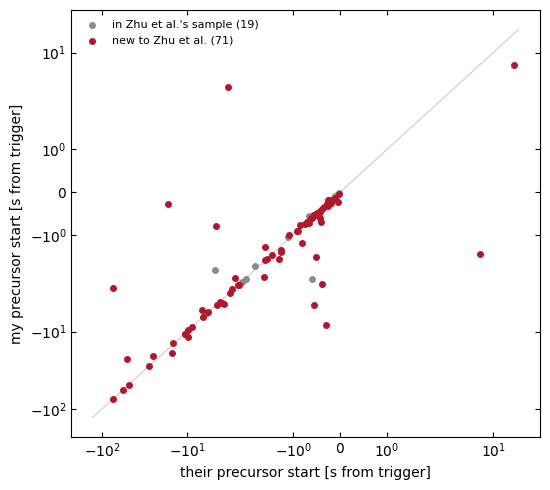

In [3]:
fig, ax = plt.subplots(figsize=(5.6, 5.0))
for t, colour, label in ((overlap, "0.55", "in Zhu et al.'s sample"), (new, "#b2182b", "new to Zhu et al.")):
    f = t[t.found]
    ax.scatter(f.their_start_s, f.our_start_s, s=16, color=colour, label=f"{label} ({len(f)})", zorder=3)
lim = [-130, 20]
ax.plot(lim, lim, color="0.8", lw=0.8, zorder=0)
ax.set(xscale="symlog", yscale="symlog", xlabel="their precursor start [s from trigger]", ylabel="my precursor start [s from trigger]")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "29_precursor_starts.png", dpi=150); plt.show()

In [4]:
found = new[new.found].copy()
found["starts_agree"] = found.starts_agree.astype(bool)
together, apart = found[found.starts_agree], found[~found.starts_agree]
print(f"starts apart: {len(apart)}, mine earlier in {int((apart.delta_start_s < 0).sum())} and later in {int((apart.delta_start_s > 0).sum())}")
print(f"starts together: {len(together)}; stops within 1 s in {int((together.delta_stop_s.abs() < 1).sum())};",
      "my precursor ends more than 10 s after theirs in", list(together.index[together.delta_stop_s > 10]))
missed = new[~new.found]
flags = pd.Series({n: json.loads((RESULTS / n / "episodes.json").read_text())["modes"]["zhu2026"].get("flags", []) for n in missed.index})
print(f"not found: {len(missed)}; no quiet gap before the main emission in {int(flags.map(lambda f: 'no_quiet_gap_before_main' in f).sum())}, "
      f"a quiet gap but the first piece not fainter than what follows in {int(flags.map(lambda f: 'pe_counts_not_below_me' in f).sum())}")

starts apart: 26, mine earlier in 15 and later in 11
starts together: 45; stops within 1 s in 20; my precursor ends more than 10 s after theirs in ['090610B', '121005B', '150226B', '160625B', '170416A', '180307A']
not found: 25; no quiet gap before the main emission in 18, a quiet gap but the first piece not fainter than what follows in 6


On the 21 bursts that are in their list and in my run of Zhu et al.'s sample, the two searches agree closely. My rule finds a precursor
in 19, and in 17 of those its start agrees with theirs (the 19 are a median 0.015 s apart). On the 96 new bursts the agreement is looser.
My rule finds a precursor in 71, starting with theirs in 45 (a median 0.08 s apart over the 71). Where the starts differ, mine is earlier
in 15 and later in 11. Of the 25 it misses, 18 have no block between their precursor and the main emission that passes as a quiet episode
at my bin, and 6 have one but more counts before it than after, so Zhu et al.'s rule doesn't count the first piece as a precursor.

The ends agree less well than the starts. Of the 45 that start together, 20 end within 1 s of theirs, and in 6 my precursor runs on more
than 10 s past theirs. GRB 160625B shows how that happens (its windows are in section 2). Zhu et al.'s quiet episode is a single block
lower than both its neighbours. The long gap between this burst's precursor and its main emission gets cut into long blocks just above the
background, on either side of one short dip, so the dip becomes the quiet episode and the precursor runs on until it. The project rule of
notebook 18, which lets a quiet gap span several blocks, ends the precursor where Coppin et al. do, within a second.

## 2. The precursor's E_peak against its main emission

Dichiara et al.'s argument is that GRB 230307A's precursor is much softer than its main emission. Here is the same ratio, the precursor's
E_peak over the main emission's, for the new bursts next to Zhu et al.'s sample and the two confirmed mergers. Both E_peaks are my rule's,
each only where it's measured, and a precursor E_peak that is only a 90% range is shown as a line.

In [5]:
zhu = collect("zhu2026")
zhu = zhu[(zhu.measured_PE.astype(str) == "True") & (zhu.measured_ME.astype(str) == "True")]
zhu_ratio = (zhu.Ep_PE_ours / zhu.Ep_ME_ours).dropna()
new_ratio = new.Ep_ratio.dropna()
mergers = {"GRB 211211A": float(zhu.loc["211211A", "Ep_PE_ours"] / zhu.loc["211211A", "Ep_ME_ours"]) if "211211A" in zhu.index else np.nan}
e = pd.read_csv("shared/epeak_230307A.csv", comment="#").set_index("label")
mergers["GRB 230307A"] = float(e.loc["pre", "Epeak_keV"] / collect("zhu2026").loc["230307A", "Ep_ME_ours"])
print(f"E_peak ratio, median: new {new_ratio.median():.2f} ({len(new_ratio)} bursts), Zhu et al.'s sample {zhu_ratio.median():.2f} ({len(zhu_ratio)})")
print("confirmed mergers:", {k: round(v, 3) for k, v in mergers.items()})
print("new bursts with a precursor softer than GRB 230307A's ratio:", int((new_ratio < mergers["GRB 230307A"]).sum()))
from scipy.stats import mannwhitneyu
from zhu.catalogue import read_table_2026
types = read_table_2026().Type.reindex(zhu_ratio.index)
type_ii, candidates = zhu_ratio[types == "II"], zhu_ratio[types.astype(str).str.startswith("I-")]
p = lambda a, b: mannwhitneyu(np.log10(a), np.log10(b)).pvalue
print(f"Zhu et al.'s sample by their type: Type II {type_ii.median():.2f} ({len(type_ii)}), merger candidates {candidates.median():.2f} "
      f"({len(candidates)}); Mann-Whitney p of the new bursts against the whole sample {p(new_ratio, zhu_ratio):.3f}, against Type II "
      f"{p(new_ratio, type_ii):.2f}, against the candidates {p(new_ratio, candidates):.4f}")

E_peak ratio, median: new 1.05 (47 bursts), Zhu et al.'s sample 0.70 (70)
confirmed mergers: {'GRB 211211A': 0.048, 'GRB 230307A': 0.188}
new bursts with a precursor softer than GRB 230307A's ratio: 2
Zhu et al.'s sample by their type: Type II 0.96 (40), merger candidates 0.55 (30); Mann-Whitney p of the new bursts against the whole sample 0.017, against Type II 0.42, against the candidates 0.0005


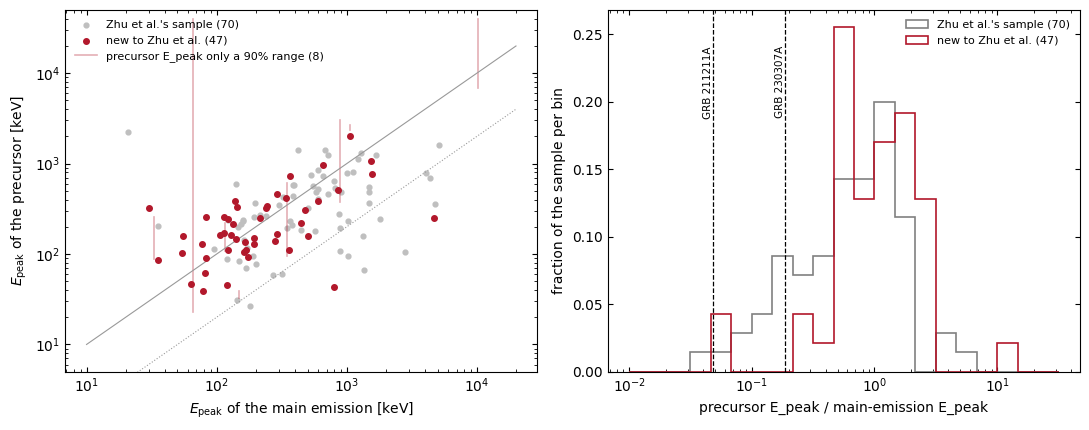

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.scatter(zhu.Ep_ME_ours, zhu.Ep_PE_ours, s=12, color="0.75", label=f"Zhu et al.'s sample ({len(zhu)})")
both = new[new.Ep_PE_measured & new.Ep_ME_measured]
ax.scatter(both.Ep_ME_keV, both.Ep_PE_keV, s=16, color="#b2182b", label=f"new to Zhu et al. ({len(both)})", zorder=3)
# a found precursor whose E_peak is only a 90% range, drawn as a line; a lower end above the band (a fit that ran away) isn't a range
rng = new[new.found & ~new.Ep_PE_measured & new.Ep_ME_measured]
rng = rng[(rng.Ep_PE_95_lo_keV.notna() | rng.Ep_PE_95_hi_keV.notna()) & ~(rng.Ep_PE_95_lo_keV > 4e4)]
for i, (_, r) in enumerate(rng.iterrows()):
    lo = r.Ep_PE_95_lo_keV if np.isfinite(r.Ep_PE_95_lo_keV) else 8.0
    hi = min(r.Ep_PE_95_hi_keV, 4e4) if np.isfinite(r.Ep_PE_95_hi_keV) else 4e4
    ax.plot([r.Ep_ME_keV] * 2, [lo, hi], color="#b2182b", alpha=0.35, lw=1.2, label=f"precursor E_peak only a 90% range ({len(rng)})" if i == 0 else None)
x = np.array([10, 2e4])
for k, style in ((1, "-"), (0.2, ":")):
    ax.plot(x, k * x, color="0.6", ls=style, lw=0.8)
ax.set(xscale="log", yscale="log", ylim=(5, 5e4), xlabel=r"$E_{\rm peak}$ of the main emission [keV]", ylabel=r"$E_{\rm peak}$ of the precursor [keV]")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax = axes[1]
bins = np.logspace(-2, 1.5, 22)
# each burst counts 1/N, so the two samples compare per bin of equal width in log10 (a density would favour the narrow low bins)
for ratio, colour, label in ((zhu_ratio, "0.5", "Zhu et al.'s sample"), (new_ratio, "#b2182b", "new to Zhu et al.")):
    ax.hist(ratio, bins=bins, weights=np.full(len(ratio), 1 / len(ratio)), histtype="step", lw=1.2, color=colour, label=f"{label} ({len(ratio)})")
for k, v in mergers.items():
    ax.axvline(v, color="k", lw=0.9, ls="--")
    ax.annotate(k, (v, ax.get_ylim()[1] * 0.9), rotation=90, fontsize=7.5, ha="right", va="top")
ax.set(xscale="log", xlabel="precursor E_peak / main-emission E_peak", ylabel="fraction of the sample per bin")
ax.legend(fontsize=8, frameon=False)
for a in axes:
    a.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "29_epeak_ratios.png", dpi=150); plt.show()

In [7]:
print(f"median ratio where the two precursor starts agree: {together.Ep_ratio.median():.2f} ({int(together.Ep_ratio.notna().sum())} bursts); "
      f"where they don't: {apart.Ep_ratio.median():.2f} ({int(apart.Ep_ratio.notna().sum())})")


def keV(x, lo, hi):
    return f"{x:.0f} -{lo:.0f} +{hi:.0f} keV" if np.isfinite(lo) and np.isfinite(hi) else f"{x:.0f} keV"


# the new bursts below GRB 230307A's ratio, on the windows of both rules (the project rule of notebook 18 beside zhu2026)
for name in new_ratio[new_ratio < mergers["GRB 230307A"]].index:
    r = new.loc[name]
    print(f"GRB {name}: Coppin et al.'s first precursor {r.their_start_s:.2f} to {r.their_stop_s:.2f} s")
    episodes = json.loads((RESULTS / name / "episodes.json").read_text())["modes"]
    for mode in ("zhu2026", "project"):
        s = pd.read_csv(RESULTS / name / f"spectra_{mode}.csv").set_index("label")
        parts = [f"{label} {episodes[mode][key][0]:.2f} to {episodes[mode][key][1]:.2f} s, E_peak "
                 f"{keV(s.loc[label, 'Epeak'], s.loc[label, 'Epeak_err_lo'], s.loc[label, 'Epeak_err_hi'])} ({s.loc[label, 'model']})"
                 for label, key in (("PE", "pe"), ("ME", "me"))]
        print(f"   {mode}: " + "; ".join(parts) + f"; ratio {s.loc['PE', 'Epeak'] / s.loc['ME', 'Epeak']:.3f}")
        if mode == "zhu2026":
            me = s.loc["ME"]
            me_flags = me.zhu_flags if isinstance(me.zhu_flags, str) else "no flags"
            print(f"      main emission their way: {keV(me.zhu_Epeak, me.zhu_Epeak_err_lo, me.zhu_Epeak_err_hi)} ({me.zhu_model}; {me_flags})")

median ratio where the two precursor starts agree: 0.79 (32 bursts); where they don't: 1.23 (15)
GRB 160625B: Coppin et al.'s first precursor -0.50 to 1.92 s
   zhu2026: PE -0.50 to 125.49 s, E_peak 43 -2 +2 keV (Comptonized); ME 125.78 to 216.30 s, E_peak 797 keV (BandLowBreak); ratio 0.054
      main emission their way: 674 -8 +8 keV (band; no flags)
   project: PE -0.50 to 0.98 s, E_peak 67 -1 +1 keV (Comptonized); ME 177.82 to 216.30 s, E_peak 789 keV (BandLowBreak); ratio 0.085
GRB 190326B: Coppin et al.'s first precursor 7.06 to 8.73 s
   zhu2026: PE -1.44 to 20.22 s, E_peak 252 -50 +87 keV (Comptonized); ME 34.75 to 230.05 s, E_peak 4676 -1789 +2018 keV (Comptonized); ratio 0.054
      main emission their way: 1617 -1216 +3448 keV (cpl; no_model_fully_constrained)
   project: PE -1.44 to 59.20 s, E_peak 268 -19 +23 keV (Comptonized); ME 229.92 to 230.05 s, E_peak 58 -6 +7 keV (Comptonized); ratio 4.609


The new precursors are about as hard as their main emissions: the median ratio is 1.05 (47 bursts), against 0.70 in Zhu et al.'s sample
(Mann-Whitney p = 0.017). The difference comes from what the two samples hold. Zhu et al.'s Type II bursts have a median of 0.96 (40), and
the new bursts can't be told from them (p = 0.42). Their merger candidates have 0.55 (30), well below the new bursts (p = 0.0005). The
ratio is also lower where my precursor starts with Coppin et al.'s (0.79, 32 bursts) than where it doesn't (1.23, 15). Either way, the
typical precursor is nothing like the mergers', whose E_peaks are 0.048 (GRB 211211A) and 0.19 (GRB 230307A) of their main emissions'.

Two new bursts come out below GRB 230307A's ratio, and neither one as the rule first has it. GRB 190326B's 0.054 rests on a main-emission
E_peak of 4.7 MeV that is uncertain by 40%, and that no model constrains fully their way (1.6 MeV, -1.2 +3.4). It comes from a window that
runs from 35 s to a lone 0.13 s spike at 230 s, and my precursor also starts 8.5 s before Coppin et al.'s. So it isn't a soft precursor
that can be relied on. GRB 160625B's 0.054 comes from a precursor window 126 s long (section 1). On the precursor alone, the project rule's
-0.50 to 0.98 s (Coppin et al.'s ends at 1.92 s), its E_peak is 67 +- 1 keV against 789 keV for the main emission. That's a ratio of 0.085,
softer than GRB 230307A's. It's a well-studied long burst at z = 1.41, and the precursor's E_peak agrees with both papers that measured it:
66.8 keV (Zhang et al. 2018, Nature Astronomy 2, 69) and 70 keV (Ravasio et al. 2018, A&A 613, A16). Zhang et al. fitted the precursor
with a blackbody and put all three episodes on the correlations of Type II (collapsar) bursts. Ravasio et al. find that a cut-off power
law fits it better than a blackbody, and so does mine. The main emission's E_peak depends on the model and on the version of GBM's
response files (notebook 33), but my 67 keV stays below GRB 230307A's ratio against the published fits that describe it: 0.10 with
Ravasio et al.'s two-break fit, and 0.15 with Zhang et al.'s Band fit. Only a smoothly broken power law that Ravasio et al. reject
(reduced chi-square 6.5) would give 0.21. So one new burst in 47 has a precursor as soft against its main emission as a merger's, in a
collapsar. A precursor much softer than its main emission doesn't make a merger by itself.

## 3. Soft and fast?

Dichiara et al.'s argument has two halves: GRB 230307A's precursor is much softer than its main emission, and yet it varies as fast.
Within a burst, softer windows usually vary more slowly, so a soft precursor that's as fast as its main emission sits off the burst's own
track. Rodrigo's MVT will test the second half on these windows. A first look comes from the T_MVT my run already reads off the blocks
(Zhu et al.'s reading, notebook 23). The precursor's value carries about 0.4 dex of counting noise (notebook 25), so this compares samples,
not single bursts. Soft here means an E_peak ratio no larger than GRB 230307A's. Fast means a precursor T_MVT no longer than the main
emission's within its 68% range (from the 16th and 84th percentiles of the simulated light curves).

In [8]:
def soft_fast(features, ratios):
    t = pd.DataFrame({"Ep_ratio": ratios})
    f = features.loc[t.index]
    t["mvt_ratio"] = f.TMVT_PE / f.TMVT_ME
    half = lambda lo, hi: 0.5 * (np.log10(hi) - np.log10(lo))
    t["mvt_ratio_err_dex"] = np.hypot(half(f.TMVT_PE_p16, f.TMVT_PE_p84), half(f.TMVT_ME_p16, f.TMVT_ME_p84))
    t["soft"] = t.Ep_ratio <= mergers["GRB 230307A"]
    t["fast"] = np.log10(t.mvt_ratio) - t.mvt_ratio_err_dex <= 0
    return t.dropna(subset=["Ep_ratio", "mvt_ratio"])


sf_zhu = soft_fast(collect("zhu2026"), zhu_ratio)
sf_new = soft_fast(collect("zhu2026", RESULTS), new_ratio)
from scipy.stats import spearmanr
for label, t in (("Zhu et al.'s sample", sf_zhu), ("new to Zhu et al.", sf_new)):
    rho, p = spearmanr(np.log10(t.Ep_ratio), np.log10(t.mvt_ratio))
    print(f"{label}: {len(t)} bursts with both ratios; soft {int(t.soft.sum())}, of them as fast as the main emission {int((t.soft & t.fast).sum())}; "
          f"not soft but as fast {int((~t.soft & t.fast).sum())} of {int((~t.soft).sum())}; median T_MVT ratio {t.mvt_ratio.median():.2f}, "
          f"its median uncertainty {t.mvt_ratio_err_dex.median():.2f} dex; Spearman of the two ratios {rho:.2f} (p {p:.2f})")
if "211211A" in sf_zhu.index:
    print("GRB 211211A:", sf_zhu.loc["211211A", ["Ep_ratio", "mvt_ratio", "mvt_ratio_err_dex", "soft", "fast"]].to_dict())
soft_new = sf_new[sf_new.soft].sort_values("Ep_ratio")
print(soft_new.round(3).to_string() if len(soft_new) else "no new burst has a precursor as soft as GRB 230307A's")

Zhu et al.'s sample: 70 bursts with both ratios; soft 9, of them as fast as the main emission 8; not soft but as fast 39 of 61; median T_MVT ratio 1.35, its median uncertainty 0.50 dex; Spearman of the two ratios 0.04 (p 0.76)
new to Zhu et al.: 47 bursts with both ratios; soft 2, of them as fast as the main emission 0; not soft but as fast 28 of 45; median T_MVT ratio 1.84, its median uncertainty 0.52 dex; Spearman of the two ratios 0.26 (p 0.08)
GRB 211211A: {'Ep_ratio': 0.04831916082045646, 'mvt_ratio': 7.0, 'mvt_ratio_err_dex': 0.44800560013880203, 'soft': True, 'fast': False}
         Ep_ratio  mvt_ratio  mvt_ratio_err_dex  soft   fast
name                                                        
190326B     0.054      9.000              0.481  True  False
160625B     0.054     10.789              0.486  True  False


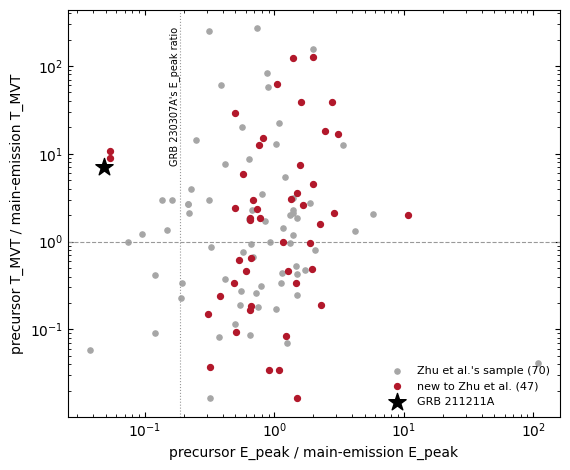

In [9]:
fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.scatter(sf_zhu.Ep_ratio, sf_zhu.mvt_ratio, s=14, color="0.65", label=f"Zhu et al.'s sample ({len(sf_zhu)})")
ax.scatter(sf_new.Ep_ratio, sf_new.mvt_ratio, s=18, color="#b2182b", label=f"new to Zhu et al. ({len(sf_new)})", zorder=3)
if "211211A" in sf_zhu.index:
    r = sf_zhu.loc["211211A"]
    ax.scatter(r.Ep_ratio, r.mvt_ratio, marker="*", s=170, color="k", zorder=4, label="GRB 211211A")
ax.axhline(1, color="0.6", lw=0.8, ls="--")
ax.axvline(mergers["GRB 230307A"], color="0.6", lw=0.8, ls=":")
ax.annotate("GRB 230307A's E_peak ratio", (mergers["GRB 230307A"], ax.get_ylim()[1]), rotation=90, fontsize=7, ha="right", va="top")
ax.set(xscale="log", yscale="log", xlabel="precursor E_peak / main-emission E_peak", ylabel="precursor T_MVT / main-emission T_MVT")
ax.legend(fontsize=8, frameon=False, loc="lower right")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "29_soft_and_fast.png", dpi=150); plt.show()

In [10]:
# GRB 160625B on the project rule's windows, whose precursor ends with Coppin et al.'s (section 2)
s = pd.read_csv(RESULTS / "160625B" / "spectra_project.csv").set_index("label")
proj = soft_fast(collect("project", RESULTS), pd.Series({"160625B": s.loc["PE", "Epeak"] / s.loc["ME", "Epeak"]}))
print(proj.round(3).to_string())
print(collect("project", RESULTS).loc["160625B", ["TMVT_PE", "TMVT_PE_p16", "TMVT_PE_p84", "TMVT_ME", "TMVT_ME_p16", "TMVT_ME_p84"]].to_dict())

         Ep_ratio  mvt_ratio  mvt_ratio_err_dex  soft   fast
160625B     0.085       1.75              0.102  True  False


{'TMVT_PE': 0.056, 'TMVT_PE_p16': 0.06, 'TMVT_PE_p84': 0.076, 'TMVT_ME': 0.032, 'TMVT_ME_p16': 0.032, 'TMVT_ME_p84': 0.048}


With 0.5 dex of counting noise in a typical T_MVT ratio, "fast" here really means "not shown to be slower", and most precursors aren't
shown to be slower: 39 of the 61 that aren't soft in Zhu et al.'s sample count as fast, and so do 28 of the 45 new ones (and 8 of Zhu et
al.'s 9 soft precursors). The two ratios aren't related in Zhu et al.'s sample (Spearman 0.04) and only weakly among the new bursts (0.26,
p = 0.08). The test can't even call GRB 211211A's precursor fast: its T_MVT is 7 times its main emission's (+-0.45 dex). So the block
T_MVT is too coarse to make the call Dichiara et al. made for GRB 230307A, and that needs Rodrigo's MVT on these windows.

On the rule's windows neither soft new burst is fast (9.0 and 10.8 times), but section 2 showed that those windows are wrong. On the
project rule's windows, GRB 160625B's precursor is soft (0.085), and its T_MVT is 56 ms against 32 ms for its main emission, 1.75 times
(+-0.10 dex). That's slower by this reading, but this reading isn't the Haar MVT. It's the burst to measure first (section 5): a soft
precursor in a collapsar that turned out as fast as its main emission would show that softness and speed together don't single out a
merger.

## 4. Zhu et al.'s EPI for the new bursts

Zhu et al.'s classifier, EPI = log10[E_p,ME^2 / (T100,PE T100,QE1^1/2 T_MVT,PE)] (their eq. 2), puts Type I (merger-like) bursts above
6.2. With my numbers it separates their own types with an area under the ROC curve of 0.98 (notebook 25). Here it is for the new bursts,
with the chance of lying above the line from the simulated light curves and E_peak's errors (features.epi_summary). E_p,ME enters
squared, so I only keep bursts whose main-emission E_peak (their way) comes from a fit with every parameter constrained, in both samples.
A new burst above the line is a merger candidate by their criterion, to set next to the soft-precursor test of section 2.

In [11]:
from zhu.catalogue import EPI_LINE
from zhu.features import epi_summary


def me_constrained(root, names):
    # E_p,ME their way from a model whose parameters are all constrained (zhu.spectra.constrained), with both errors
    out = {}
    for n in names:
        path = root / n / "spectra_zhu2026.csv"
        s = pd.read_csv(path).set_index("label") if path.exists() else pd.DataFrame()
        me = s.loc["ME"] if "ME" in s.index else None
        out[n] = me is not None and "no_model_fully_constrained" not in str(me.zhu_flags) and bool(np.isfinite(me.zhu_Epeak_err_lo) and np.isfinite(me.zhu_Epeak_err_hi))
    return pd.Series(out, dtype=bool)


epi_zhu = epi_summary(collect("zhu2026"), ZHU_RESULTS, way="zhu")
epi_zhu["Type"] = pd.read_csv("shared/zhu2026_table1.csv", comment="#", dtype={"GRB": str}).set_index("GRB").Type
epi_new = epi_summary(collect("zhu2026", RESULTS).loc[new.index], RESULTS, way="zhu").join(new[["Ep_ratio"]])
for label, t, root in (("Zhu et al.'s sample", epi_zhu, ZHU_RESULTS), ("new to Zhu et al.", epi_new, RESULTS)):
    t["constrained"] = me_constrained(root, t.index)
    loose = t[t.EPI_zhu.notna() & ~t.constrained]
    ep = collect("zhu2026", root).Ep_ME_zhu
    print(f"{label}: {int(t.EPI_zhu.notna().sum())} with an EPI, {len(loose)} of them with an unconstrained E_p,ME:",
          ", ".join(f"{n} (EPI {v:.1f}, E_p,ME {ep.get(n, np.nan):.3g} keV)" for n, v in loose.EPI_zhu.items()))
epi_zhu, epi_new = epi_zhu[epi_zhu.constrained], epi_new[epi_new.constrained]
print(f"median EPI: new {epi_new.EPI_zhu.median():.1f}, Zhu et al.'s Type II {epi_zhu.EPI_zhu[epi_zhu.Type.eq('II')].median():.1f}, "
      f"their Type I {epi_zhu.EPI_zhu[epi_zhu.Type.str.startswith('I-', na=False)].median():.1f}")
above = epi_new[epi_new.P_above_zhu > 0.5].sort_values("EPI_zhu", ascending=False)
f = collect("zhu2026", RESULTS)
above = above.join(f[["T100_PE", "T100_QE1", "Tres", "TMVT_PE", "TMVT_PE_p16", "TMVT_PE_p84"]]).join(sample[["t90"]])
print(f"{int(epi_new.EPI_zhu.notna().sum())} new bursts with an EPI; above the line ({EPI_LINE}) with a chance over one half: {len(above)}")
print(above.drop(columns="constrained").round(3).to_string() if len(above) else "none")
both = above[above.Ep_ratio <= mergers["GRB 230307A"]]
print("above the line and with a precursor as soft as GRB 230307A's:", list(both.index) or "none")

Zhu et al.'s sample: 95 with an EPI, 3 of them with an unconstrained E_p,ME: 090131A (EPI 4.7, E_p,ME 65 keV), 170310A (EPI 7.0, E_p,ME 6.54e+03 keV), 211023A (EPI 0.4, E_p,ME 147 keV)


new to Zhu et al.: 71 with an EPI, 14 of them with an unconstrained E_p,ME: 081121A (EPI 4.6, E_p,ME 189 keV), 100619A (EPI 2.9, E_p,ME 80.1 keV), 120513A (EPI 4.2, E_p,ME 153 keV), 121005B (EPI 1.6, E_p,ME 122 keV), 130318A (EPI 14.1, E_p,ME 2.17e+08 keV), 130623B (EPI 4.1, E_p,ME 313 keV), 130720B (EPI 3.4, E_p,ME 95.9 keV), 140104B (EPI 5.6, E_p,ME 5.87e+03 keV), 150226B (EPI 2.7, E_p,ME 342 keV), 161117A (EPI 0.8, E_p,ME 56.3 keV), 170416A (EPI 6.2, E_p,ME 1.39e+04 keV), 190326B (EPI 5.3, E_p,ME 1.62e+03 keV), 190901A (EPI 2.0, E_p,ME 900 keV), 191101B (EPI 2.0, E_p,ME 90.6 keV)
median EPI: new 2.7, Zhu et al.'s Type II 4.3, their Type I 8.1


57 new bursts with an EPI; above the line (6.2) with a chance over one half: 6
         EPI_zhu  EPI_p16_zhu  EPI_p84_zhu  P_above_zhu  Ep_ratio  T100_PE  T100_QE1   Tres  TMVT_PE  TMVT_PE_p16  TMVT_PE_p84     t90
GRB                                                                                                                                   
090929A    8.218        8.057        8.871        1.000     0.316    0.304     0.432  0.016    0.008        0.008        0.056   6.174
140917A    7.443        6.877        7.891        0.993     0.491    1.536     1.312  0.032    0.048        0.048        0.554  16.512
181122A    7.307        6.828        7.828        0.939     1.465    0.320     1.600  0.032    0.048        0.016        0.080  73.728
180929A    6.874        6.480        8.063        0.934     0.599    0.544     1.984  0.032    0.112        0.048        0.432   2.944
091109C    6.856        6.556        7.358        0.996     0.901    0.304     0.704  0.016    0.008        0.0

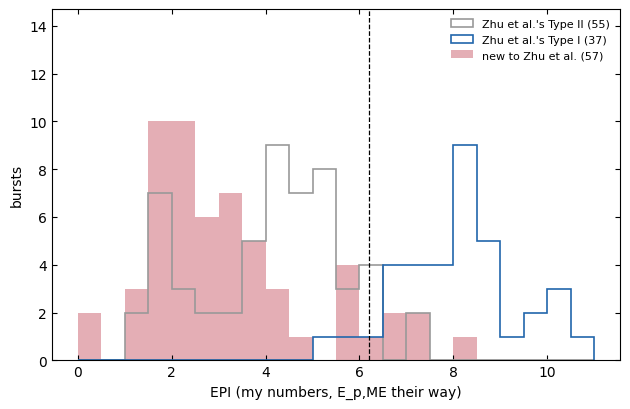

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
bins = np.arange(0, 11.01, 0.5)
for label, sel, colour in (("Zhu et al.'s Type II", epi_zhu.Type.eq("II"), "0.6"), ("Zhu et al.'s Type I", epi_zhu.Type.str.startswith("I-"), "#2166ac")):
    ax.hist(epi_zhu.EPI_zhu[sel].dropna(), bins=bins, histtype="step", lw=1.2, color=colour, label=f"{label} ({int(epi_zhu.EPI_zhu[sel].notna().sum())})")
ax.hist(epi_new.EPI_zhu.dropna(), bins=bins, histtype="stepfilled", alpha=0.35, color="#b2182b", label=f"new to Zhu et al. ({int(epi_new.EPI_zhu.notna().sum())})")
ax.axvline(EPI_LINE, color="k", ls="--", lw=0.9)
ax.set(xlabel="EPI (my numbers, E_p,ME their way)", ylabel="bursts")
ax.set_ylim(0, 1.4 * ax.get_ylim()[1])
ax.legend(fontsize=8, frameon=False, loc="upper right")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "29_epi.png", dpi=150); plt.show()

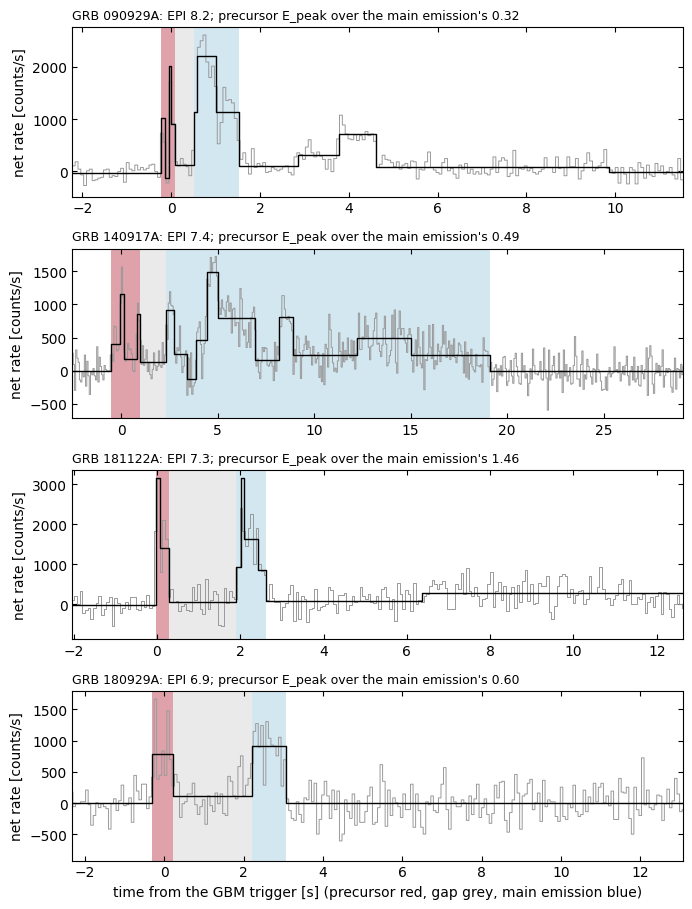

In [13]:
show = above.head(4)
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(7.0, 2.3 * len(show)), squeeze=False)
    for ax, (name, r) in zip(axes[:, 0], show.iterrows()):
        d = np.load(RESULTS / name / "light_curve.npz")
        e = json.loads((RESULTS / name / "episodes.json").read_text())["modes"]["zhu2026"]
        k = max(1, int(round(0.064 / float(d["tres"]))))            # drawn in 64 ms bins
        n = (len(d["counts"]) // k) * k
        left = d["edges"][:n:k]
        net = (d["counts"][:n] - d["background"][:n]).reshape(-1, k).sum(1) / (k * float(d["tres"]))
        ax.step(left, net, where="post", color="0.6", lw=0.7)
        b = pd.read_csv(RESULTS / name / "blocks.csv")
        ax.step(np.r_[b.start, b.stop.iloc[-1]], np.r_[b.rate, b.rate.iloc[-1]], where="post", color="k", lw=1.0)
        for key, colour in (("pe", "#b2182b"), ("qe1", "0.8"), ("me", "#92c5de")):
            if e.get(key):
                ax.axvspan(*e[key], color=colour, alpha=0.4, lw=0)
        ax.set_xlim(e["pe"][0] - 2, e["me"][1] + 10)
        ratio = f"{r.Ep_ratio:.2f}" if np.isfinite(r.Ep_ratio) else "not measured"
        ax.set_title(f"GRB {name}: EPI {r.EPI_zhu:.1f}; precursor E_peak over the main emission's {ratio}", fontsize=9, loc="left")
        ax.set_ylabel("net rate [counts/s]")
        ax.tick_params(which="both", direction="in", top=True, right=True)
    axes[-1, 0].set_xlabel("time from the GBM trigger [s] (precursor red, gap grey, main emission blue)")
    fig.tight_layout(); fig.savefig(FIGURES / "29_epi_candidates.png", dpi=150); plt.show()

An unconstrained main-emission E_peak enters EPI squared, and among the new bursts such fits are common: 14 of 71, against 3 of 95 in Zhu
et al.'s sample. Left in, GRB 130318A would top the list with an EPI of 14.1, from an E_peak of 2e8 keV. Of the 57 left, most sit below Zhu
et al.'s Type II bursts (a median EPI of 2.7, against 4.3 for their Type II and 8.1 for their Type I). They have long precursors and long
gaps, which EPI counts against a merger.

Six are above the line with a better than even chance: GRB 090929A (8.2), 140917A (7.4), 181122A (7.3), 180929A (6.9), 091109C (6.9) and
150127A (6.4). They have the shape EPI rewards, a short precursor (under 1 s in four of them, and at most 2.1 s) and a gap of 0.4 to 2 s
before the main emission. But their T90s run from 2.9 to 74 s, and two of them rest on the floor of the T_MVT reading: half a bin (8 ms)
in GRB 090929A and 091109C, where 091109C's simulated light curves give 56 to 266 ms (16th to 84th percentiles). None of the six has a soft
precursor (ratios 0.32 to 1.93), and no soft precursor is above the line, so on these bursts Zhu et al.'s classifier and Dichiara's
softness pick out different bursts. GRB 090929A is the most merger-like by EPI, with all its draws above the line: a 0.3 s precursor, then
a 1 s main pulse 0.4 s later, and a weaker bump at 3 to 5 s, in a T90 of 6.2 s.

## 5. Windows for the MVT

These are the precursor and main-emission windows of every new burst in which my rule finds both, in the format of
`windows_zhu_sample.csv`, for Rodrigo's MVT. A soft precursor (an E_peak ratio below GRB 230307A's) is the case Dichiara's argument is
about, so those come first. Where my precursor runs on more than 10 s past Coppin et al.'s and the project rule's ends within a second of
theirs (section 1), the project rule's windows go to a second file, so that the MVT can also be measured on the precursor alone.

In [14]:
w = A.windows(RESULTS)
w.to_csv("results/coppin/windows_coppin_sample.csv", index=False)
soft = new[new.Ep_ratio < mergers["GRB 230307A"]].sort_values("Ep_ratio")
print(len(w) // 2, "bursts with both windows;", len(soft), "with a precursor softer than GRB 230307A's ratio")
if len(soft):
    print(soft[["Ep_PE_keV", "Ep_ME_keV", "Ep_ratio", "our_start_s", "our_stop_s"]].round(3).to_string())
pw = A.windows(RESULTS, mode="project")
pw["name"] = pw.burst.str.replace("GRB", "")
pre = pw[pw.label == "pre"].set_index("name")
late = together[together.delta_stop_s > 10]
keep = [n for n in late.index if n in pre.index and abs(pre.loc[n, "t_stop"] - late.loc[n, "their_stop_s"]) < 1]
pw = pw[pw.name.isin(keep)].drop(columns="name")
pw.to_csv("results/coppin/windows_coppin_project_rule.csv", index=False)
print("project-rule windows written for", keep)
print(pw[["burst", "label", "t_start", "t_stop", "source"]].to_string(index=False))

71 bursts with both windows; 2 with a precursor softer than GRB 230307A's ratio
         Ep_PE_keV  Ep_ME_keV  Ep_ratio  our_start_s  our_stop_s
name                                                            
190326B    251.715   4675.789     0.054       -1.440      20.224
160625B     43.057    797.227     0.054       -0.504     125.488
project-rule windows written for ['090610B', '160625B']
     burst label  t_start  t_stop                                        source
GRB090610B   pre   -4.480   2.240 project rule, code git:c2a1f44 zhu:c8b31365a8
GRB090610B  main   86.080 132.736 project rule, code git:c2a1f44 zhu:c8b31365a8
GRB160625B   pre   -0.504   0.984 project rule, code git:c2a1f44 zhu:c8b31365a8
GRB160625B  main  177.816 216.296 project rule, code git:c2a1f44 zhu:c8b31365a8
